In [1]:
import pandas as pd
import joblib
from pathlib import Path

data_path = Path("../Day48/cleaned_customer_data.csv")
model_path = Path("../Day50/optimized_decision_tree.joblib")

df = pd.read_csv(data_path)
model = joblib.load(model_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Model loaded successfully!")
print("Target column: profit_status")
print("\nDataset columns:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (51290, 28)
Model loaded successfully!
Target column: profit_status

Dataset columns:
['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_name', 'segment', 'state', 'country', 'market', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'shipping_cost', 'order_priority', 'year', 'shipping_days', 'profit_margin', 'order_month', 'order_day', 'order_day_of_week', 'sales_category', 'profit_status']


In [2]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": model.feature_names_in_,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

Top 10 Important Features:


,Feature,Importance
1,discount,0.977047
45,market_US,0.008025
25,sub_category_Storage,0.007466
10,category_Office Supplies,0.003853
2,shipping_cost,0.001654
17,sub_category_Copiers,0.000955
37,region_South,0.000515
3,shipping_days,0.000233
13,sub_category_Art,0.000103
44,market_LATAM,0.000086


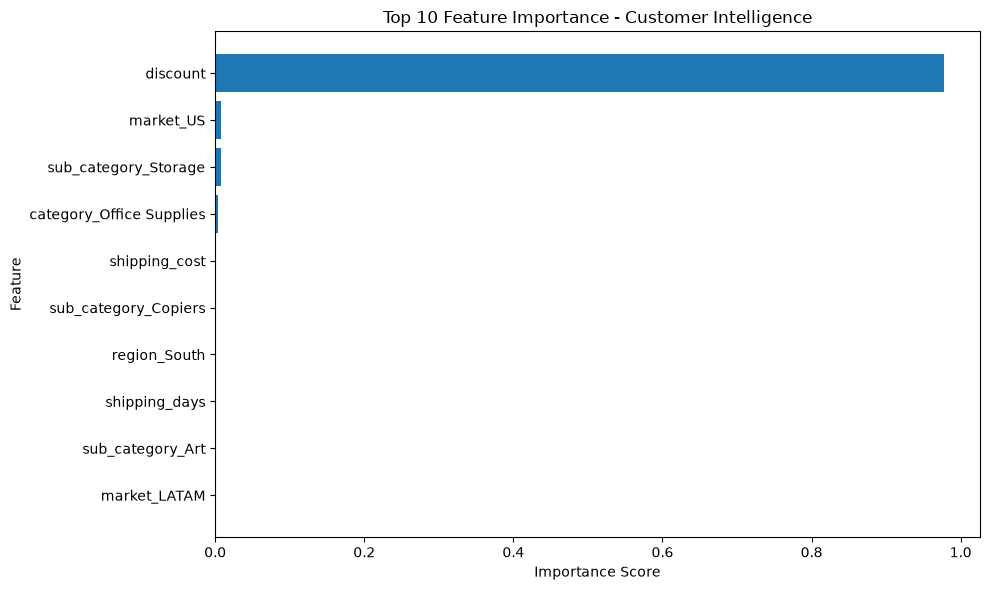

Feature importance graph saved successfully!


In [3]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(10).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Feature Importance - Customer Intelligence")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig("../Day51/feature_importance.png", dpi=300)
plt.show()

print("Feature importance graph saved successfully!")

In [4]:
from sklearn.tree import export_text

tree_rules = export_text(
    model,
    feature_names=list(model.feature_names_in_),
    max_depth=5
)

print("Decision Tree Rules:")
print(tree_rules)

Decision Tree Rules:
|--- discount <= 0.20
|   |--- discount <= 0.04
|   |   |--- market_US <= 0.50
|   |   |   |--- sub_category_Art <= 0.50
|   |   |   |   |--- sub_category_Storage <= 0.50
|   |   |   |   |   |--- class: Profit
|   |   |   |   |--- sub_category_Storage >  0.50
|   |   |   |   |   |--- class: Profit
|   |   |   |--- sub_category_Art >  0.50
|   |   |   |   |--- market_LATAM <= 0.50
|   |   |   |   |   |--- class: Profit
|   |   |   |   |--- market_LATAM >  0.50
|   |   |   |   |   |--- class: Profit
|   |   |--- market_US >  0.50
|   |   |   |--- sub_category_Storage <= 0.50
|   |   |   |   |--- sub_category_Fasteners <= 0.50
|   |   |   |   |   |--- class: Profit
|   |   |   |   |--- sub_category_Fasteners >  0.50
|   |   |   |   |   |--- class: Profit
|   |   |   |--- sub_category_Storage >  0.50
|   |   |   |   |--- shipping_cost <= 0.23
|   |   |   |   |   |--- class: Break-even
|   |   |   |   |--- shipping_cost >  0.23
|   |   |   |   |   |--- class: Profit
|  

In [5]:
from sklearn.model_selection import train_test_split

features = [
    "segment", "ship_mode", "category", "sub_category", "region", "market",
    "order_priority", "quantity", "discount", "shipping_cost",
    "shipping_days", "order_month"
]

X = pd.get_dummies(df[features].copy(), drop_first=True)

# Match the features used when training the saved model
X = X.reindex(columns=model.feature_names_in_, fill_value=0)

y = df["profit_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

customer = X_test.iloc[[0]]
prediction = model.predict(customer)[0]

print("Customer Prediction:", prediction)
print("\nTop features used by the model:")
display(feature_importance.head(5))

Customer Prediction: Profit

Top features used by the model:


,Feature,Importance
1,discount,0.977047
45,market_US,0.008025
25,sub_category_Storage,0.007466
10,category_Office Supplies,0.003853
2,shipping_cost,0.001654


In [6]:
from pathlib import Path

output_dir = Path("../Day51")
output_dir.mkdir(exist_ok=True)

feature_importance.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

print("Feature importance results saved successfully!")
print("File: Day51/feature_importance.csv")

Feature importance results saved successfully!
File: Day51/feature_importance.csv


In [7]:
from pathlib import Path

output_dir = Path("../Day51")
output_dir.mkdir(exist_ok=True)

feature_importance.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

print("Feature importance results saved successfully!")
print("Top 5 features:")
display(feature_importance.head(5))

Feature importance results saved successfully!
Top 5 features:


,Feature,Importance
1,discount,0.977047
45,market_US,0.008025
25,sub_category_Storage,0.007466
10,category_Office Supplies,0.003853
2,shipping_cost,0.001654
